[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/IMForg-Public/imf_big_data_workshop_sti26/blob/main/notebooks/BDC_Trade_Nowcasting_AIS_Portwatch.ipynb)

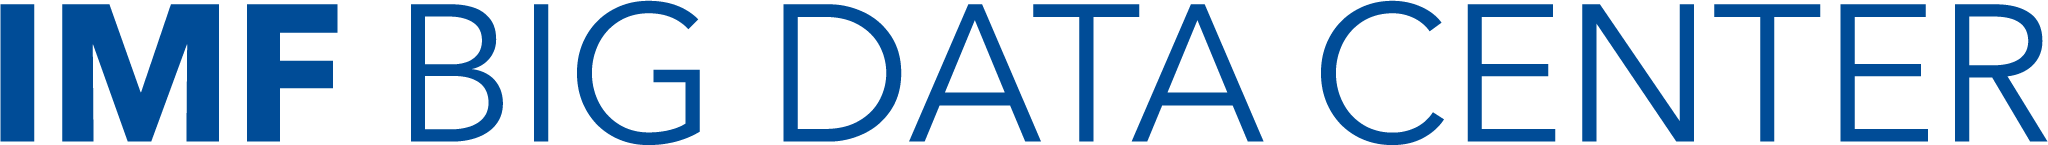

# Global Trade Nowcasting using PortWatch Data

---

<br>**Contributors:** [Alessandra Sozzi](asozzi@imf.org) & [Mario Saraiva](msaraiva@imf.org)
<br> **Last update:** Oct-2026
<br> **Description:** This notebook implements the IMF PortWatch Nowcasting of Global Trade methodology.
<br> **References:**

You may access the full methodology through the [IMF Working Paper](https://www.imf.org/en/Publications/WP/Issues/2025/05/16/Nowcasting-Global-Trade-from-Space-566957) -  *Arslanalp S., S. M. Choi, P. Kamali, R. Koepke, M. McKetty, M. Ruta, M. Saraiva, A. Sozzi, and J. Verschuur (2025), "Nowcasting Global Trade from Space," IMF Working Paper 2025/093.*

## Goal
Build monthly global trade estimates (value & volume) aligned with how official statistics are compiled.

---

## What we add
- **Timeliness:** Monthly index at ~T+7 business days.  
- **Transparent, replicable inputs.**  
- **Single global method:** One consistent aggregation across ports & vessel types, independent of national release calendars.  
- **Empirical performance:** High fit with benchmark official series; captures major turning points.

---

## Problem
Physical shipment volumes ≠ economic trade volume (e.g., heavy commodities vs high-value manufactures).

## Why Physical Volume ≠ Trade Volume
### Example

* A country imports:
  * **10 cars** each car is 2 tons and costs **20,000 USD per ton**
  * **20 tons** of rice (at **500 USD per ton**).

* Next year, the country imports **20 cars** and **20 tons of rice** at the same prices.  

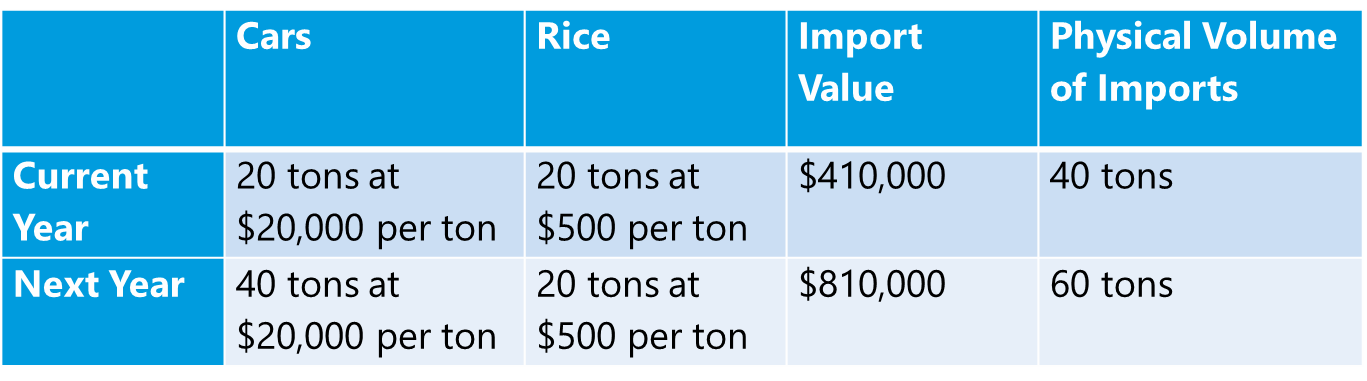
---

**Import Value:** ↑ 100%  
**Physical Volume:** ↑ 50%  
**Official Trade Volume (value deflated by price):** ↑ 100%

> **This tells us that simply aggregating the physical volume of traded goods is not an accurate measure of trade volume as measured by official statistics, particularly when unit values differ**.

## Nowcasting: From Satellite Data to Trade Estimates

### Methodology

1. **Physical Volume**  
   Use AIS data to estimate cargo volume (in metric tons) by vessel type: tankers, dry bulk, and containers.

2. **Trade Value**  
   Multiply physical volume by vessel-type-specific unit values (US$/ton), derived from trade data.

3. **Trade Volume**  
   Deflate trade value using export/import price indices to obtain trade volume in constant prices.

   

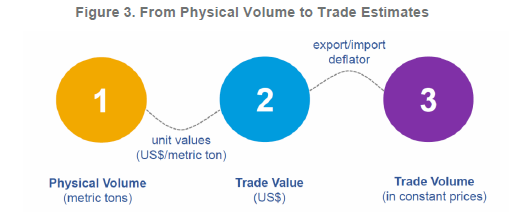


The final output is a **global trade nowcast**.




The main steps in this notebook are the following:

> **Step 1: Build the global vessels shipments in Physical volume (metric tons)**
  - Retrieve PortWatch data for all World Economic Outlook (WEO) regions and the World by 3 major vessel categories: cargo, dry bulk and tanker

> **Step 2: Build the Global Trade Value Index:**
  - Build the prices for each vessel category
    - Build the unit values for the base year: retrieve Baci $/MT unit values
    - Retrive Price Indexes per vessel category
    - Calculate the change in unit values per vessel category
  - Compute Values: prices X portwatch physical volumes

> **Step 3: Build the Global Trade Volume Index**:  
  - Compute Export/Import Deflators
  - Compute Volumes

> *Note: All series are calculated as indices with 2019 as base year*




<h2> Last words before we begin </h2>

<h5> Reminders </h5>

> - ✅ Adjust the path string to your environment
> - ✅ Generate your API Key from the World Trade Organization [WTO API PORTAL](https://apiportal.wto.org/)
> - ✅ The notebook makes request to several APIs, but a dataset has saved as backup. Note the comment #DATA BACKUP throughout the cells.






## Setup

#### Mount the drive and adjust the path

In [ ]:
# Mount the drive to access files in the Google Drive folder
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:
# Set the main path for the workshop files

import os

ROOT = "/content/drive/MyDrive/imf_big_data_workshop_sti26-main"
data_path = os.path.join(ROOT, "data", "portwatch_nowcast")
portwatch_library_dir = os.path.join(ROOT, "portwatch_py")

# Check if working
print("Data path found: ", os.path.exists(data_path))
print("File path found: ", os.path.exists(portwatch_library_dir))

Data path found:  True
File path found:  True


### Libraries

<H4> Installing Additional Library </H4>

In [ ]:
%%capture
!pip install sdmx1

<H4> PortWatch Nowcasting libraries </H4>

In [ ]:
#This allow us to source the functions in the pw_nowcasting_functions.py file
import sys
sys.path.append(portwatch_library_dir)

from pw_nowcasting_functions import (
                     ### Functions 1 - Load PortWatch Local Data
                     fetch_portwatch_local, tweak_portwatch_local,

                     ####Functions 2 - Fetch, Tweak and Compile
                     fetch_cpb, tweak_cpb,
                     compile_price_indexes, to_prices, to_laspeyres_price_index,
                     to_value_series,
                     to_volume_weighted_series,
                     fetch_baci_local,

                     #### Functions 3 - Utilities and Calculations
                     bound_dates, to_index,
                     moving_avg, growth_rate, correlate, fetch_and_tweak

                     )

<H4> General libraries </H4>

In [ ]:
import time
import json
import pandas as pd
import numpy as np
import requests
import matplotlib.pyplot as plt

### Set the latest month for which we have full data

In [ ]:
LAST_MONTH = '2026-09-30'

### Set the Country for this Excercise

In [ ]:
country_id = 'WLD'

## Portwatch data

#### Load data

**Brief function description**

> 🔍`fetch_portwatch_local(filepath)`
  - Loads a local PortWatch CSV file.

> 🔍`tweak_portwatch_local(df, iso3, start_date, end_date)`  
  - Aggregate daily AIS-based shipment data by vessel type across all tracked ports (for gloabal).
    - **Tankers**: Oil, gas, chemical products
    - **Dry Bulk Carriers**: Coal, grains, iron ore
    - **Cargo**: Manufactured goods, general cargo, Ro-Ro
  - iso3 can be 'WLD' (to aggregate everything at global level), can be a specific country, or a list of countries.
  - Applies final data cleaning or filtering.
  - Monthly totals are in metric tons.

**If you want PortWatch most recent data**

  🥷 For more recent data you can use the link below to download the latest portwatch data:

> https://portwatch.imf.org/datasets/83b1bbc7b3354c5fb1f40673bb8f852e/about

In [ ]:
# PortWatch Aggregated Data: Daily portcalls and import/export physical volumes for the 5 ship types

portwatch_local_filepath = os.path.join(data_path, "Daily_Country_Portcalls_and_Volume_Estimates.csv")
print("Last edit time: ", time.ctime(os.path.getmtime(portwatch_local_filepath)))

portwatch_raw =  fetch_portwatch_local(portwatch_local_filepath)

portwatch =  tweak_portwatch_local(portwatch_raw,
                                   iso3 = country_id, # aggregate data given the country id provided
                                   end_date=LAST_MONTH)
portwatch.tail()

Last edit time:  Sun Nov  1 02:43:34 2026
Latest Observation:  2026-10-23
Processing group WLD ...


cargo                dry_bulk                  tanker  \
                export      import      export      import      export   
date                                                                     
2026-05-01  1539665779  1544109046  1879624934  1813639000  1243793097   
2026-06-01  1517617964  1491177226  1853333886  1807370118  1258820183   
2026-07-01  1512550291  1525624681  1755763202  1840664700  1252214404   
2026-08-01  1515380113  1493187708  1762849393  1747332165  1198253452   
2026-09-01  1490647983  1467341058  1710822993  1710067828  1141190046   

                        
                import  
date                    
2026-05-01  1431765352  
2026-06-01  1379462502  
2026-07-01  1484059965  
2026-08-01  1426898807  
2026-09-01  1342700090

In [ ]:
# Get World Physical Volumes for a given month
portwatch.loc['2026-09']

cargo                dry_bulk                  tanker  \
                export      import      export      import      export   
date                                                                     
2026-09-01  1490647983  1467341058  1710822993  1710067828  1141190046   

                        
                import  
date                    
2026-09-01  1342700090

#### Plot

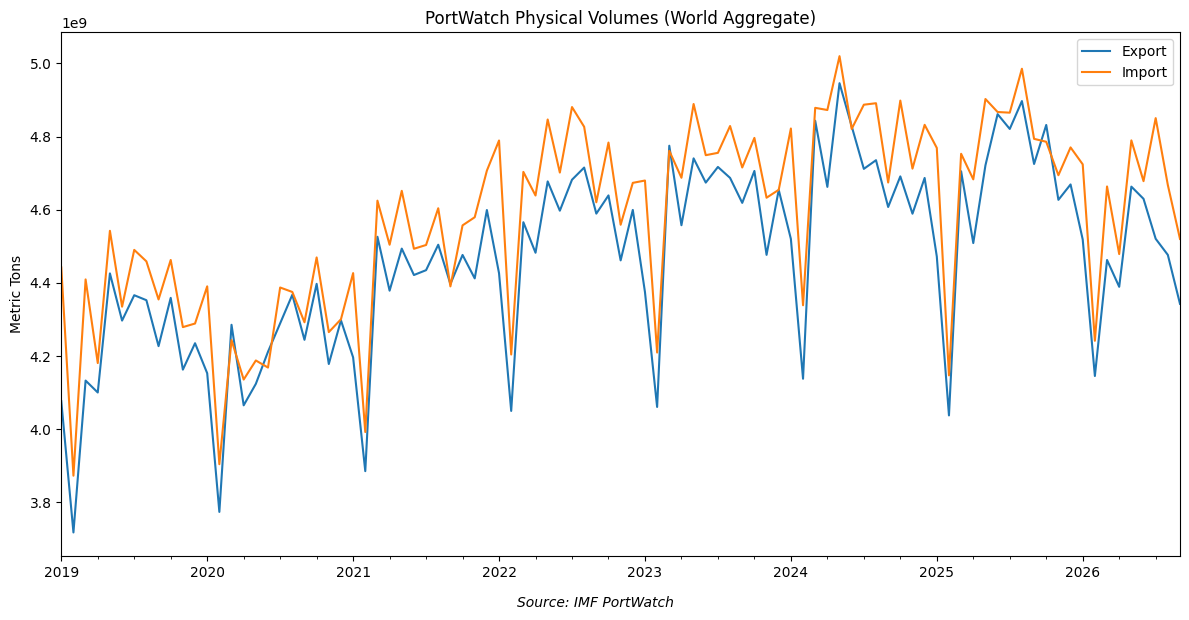

In [ ]:
# Create a figure for better layout control
plt.figure(figsize=(12, 6))

# --- Export series ---
export_series = (
    portwatch[('cargo', 'export')] +
    portwatch[('dry_bulk', 'export')] +
    portwatch[('tanker', 'export')]
)
export_series.plot(label='Export')

# --- Import series ---
import_series = (
    portwatch[('cargo', 'import')] +
    portwatch[('dry_bulk', 'import')] +
    portwatch[('tanker', 'import')]
)
import_series.plot(label='Import')

# Plot formatting
plt.legend()
plt.title("PortWatch Physical Volumes (World Aggregate)")
plt.ylabel("Metric Tons")
plt.xlabel("")

# Add footnote below the plot
plt.figtext(0.5, -0.02, "Source: IMF PortWatch", ha='center', fontsize=10, style='italic')

plt.tight_layout()
plt.show()


## Baci $/MT unit values

<h3 style="font-family: Arial, sans-serif; margin-bottom: 10px;">
  Sample BACI data showing Brazilian exports of Soy beans
</h3>
<p style="font-size: 8px; font-style: italic; color: #555; margin-top: 8px;">The CEPII BACI is a unique database that provides harmonized trade data at the country and product level (6-digit HS codes) in both value (US$) and volume terms (metric tons).</p>
<p style="font-size: 8px; font-style: italic; color: #555; margin-top: 8px;">
  Source: Retrieved from  :
  <a href="https://www.cepii.fr/CEPII/en/bdd_modele/bdd_modele_item.asp?id=37" target="_blank">
    CEPII BACI
  </a>
</p>

<table style="border-collapse: collapse; width: 100%; font-family: Arial, sans-serif; font-size: 14px;">
  <thead style="background-color: #1f4e79; color: white;">
    <tr>
      <th style="border: 1px solid #ddd; padding: 8px;">Year</th>
      <th style="border: 1px solid #ddd; padding: 8px;">Exporter</th>
      <th style="border: 1px solid #ddd; padding: 8px;">Importer</th>
      <th style="border: 1px solid #ddd; padding: 8px;">Product Code</th>
      <th style="border: 1px solid #ddd; padding: 8px;">Product Label</th>
      <th style="border: 1px solid #ddd; padding: 8px;">Value (US$)</th>
      <th style="border: 1px solid #ddd; padding: 8px;">Quantity (Metric Tons)</th>
    </tr>
  </thead>
  <tbody>
    <tr style="background-color: #f9f9f9;">
      <td style="border: 1px solid #ddd; padding: 8px;">2023</td>
      <td style="border: 1px solid #ddd; padding: 8px;">BRAZIL</td>
      <td style="border: 1px solid #ddd; padding: 8px;">Pakistan</td>
      <td style="border: 1px solid #ddd; padding: 8px;">120110</td>
      <td style="border: 1px solid #ddd; padding: 8px;">Soya beans: seed, whether or not broken</td>
      <td style="border: 1px solid #ddd; padding: 8px;">$22,223.95</td>
      <td style="border: 1px solid #ddd; padding: 8px;">37,674.64</td>
    </tr>
    <tr>
      <td style="border: 1px solid #ddd; padding: 8px;">2023</td>
      <td style="border: 1px solid #ddd; padding: 8px;">BRAZIL</td>
      <td style="border: 1px solid #ddd; padding: 8px;">Malaysia</td>
      <td style="border: 1px solid #ddd; padding: 8px;">120110</td>
      <td style="border: 1px solid #ddd; padding: 8px;">Soya beans: seed, whether or not broken</td>
      <td style="border: 1px solid #ddd; padding: 8px;">$9,769.08</td>
      <td style="border: 1px solid #ddd; padding: 8px;">16,076.20</td>
    </tr>
    <tr style="background-color: #f9f9f9;">
      <td style="border: 1px solid #ddd; padding: 8px;">2023</td>
      <td style="border: 1px solid #ddd; padding: 8px;">BRAZIL</td>
      <td style="border: 1px solid #ddd; padding: 8px;">Paraguay</td>
      <td style="border: 1px solid #ddd; padding: 8px;">120110</td>
      <td style="border: 1px solid #ddd; padding: 8px;">Soya beans: seed, whether or not broken</td>
      <td style="border: 1px solid #ddd; padding: 8px;">$4,174.72</td>
      <td style="border: 1px solid #ddd; padding: 8px;">3,407.92</td>
    </tr>
  </tbody>
</table>



**How can we construct the unit values?**  

Complementing this data with a mapping between vessel types and HS codes, provided by Cerdeiro, Komaromi, Liu, and Saeed (2020), we can calculate the average unit value of goods exported/imported by vessel type for the base period (2019).   

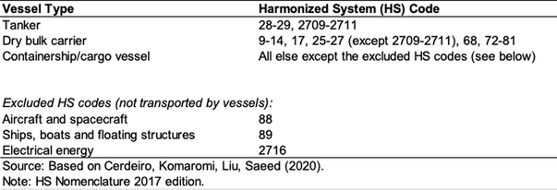

#### Load data

In [ ]:
# Load the pre-computed BACI unit values for the World, different country aggregates and individual countries

baci_filepath = os.path.join(data_path, 'baci_usd_per_ton.csv')

baci_usd_per_ton = fetch_baci_local(baci_filepath,
                                    iso3=country_id)

baci_usd_per_ton

index   cargo         dry_bulk        tanker       
       export  import   export import export import
WLD    4350.0  4350.0    288.0  288.0  539.0  539.0

#### Plot

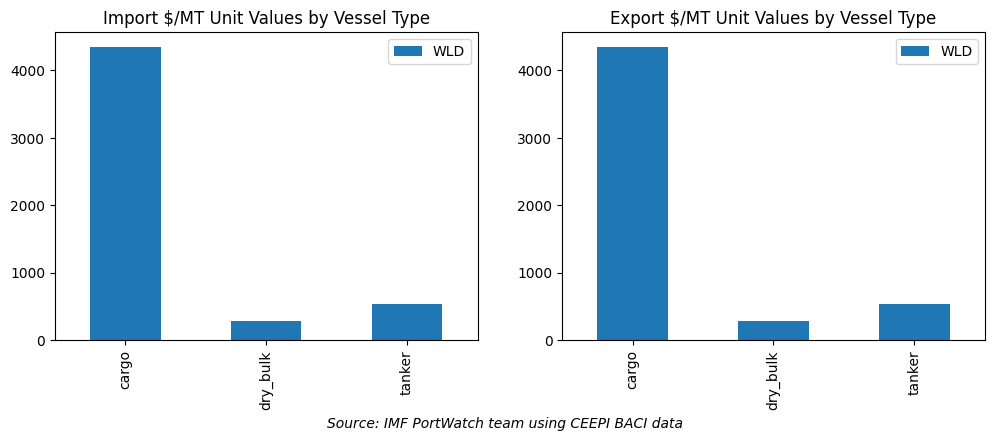

In [ ]:
# Create two subplots: one for import, one for export
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(12, 4))

# --- Plot Import Price Indexes ---
baci_usd_per_ton.loc['WLD'].xs('import', axis=0, level=1).plot.bar(
    legend=True,
    ax=axs[0],
    title=f"Import $/MT Unit Values by Vessel Type",
    xlabel=''
)

# --- Plot Export Price Indexes ---
baci_usd_per_ton.loc['WLD'].xs('export', axis=0, level=1).plot.bar(
    legend=True,
    ax=axs[1],
    title=f"Export $/MT Unit Values by Vessel Type",
    xlabel=''
)


# Add a footnote below the entire figure
fig.text(0.5, -0.1, 'Source: IMF PortWatch team using CEEPI BACI data',
         ha='center', va='center', fontsize=10, style='italic');


## Prices

#### Global Price Indexes by Ship Type

> Generate your API Key from the World Trade Organization [WTO API PORTAL](https://apiportal.wto.org/)


In [ ]:
#It is a good practice to store your API Key in CoLab's "SECRET"
#It is similar to an environmental variable.
#(see the key symbol on the left menu)
#The code below imports the API key named 'WTO_API_KEY' without revealing the actual key.

from google.colab import userdata
wto_api_key = userdata.get('WTO_API_KEY')

**Brief function description**

>🔍`compile_price_indexes`

> This function compiles a harmonized table of price indexes for three major maritime vessel types:

> - Tanker: IMF fuel prices (excluding coal)

> - Dry Bulk: IMF non-fuel commodities + coal (excluding precious metals)

> - Cargo: WTO unit value indexes (imports and exports), extended using US CPI index and Cleveland FED US CPI nowcast.

In [ ]:
# compile_price_indexes function compiles all price indexes dircetly from APIs
# and always return the latest values
price_indexes = compile_price_indexes(wto_api_key=wto_api_key, end_date=LAST_MONTH)

# Check the columns of the DataFrame
price_indexes.tail()

cargo                dry_bulk                  tanker  \
                export      import      export      import      export   
date                                                                     
2026-05-01  123.500000  125.300000  164.882091  164.882091  235.110824   
2026-06-01  123.200000  124.900000  159.551372  159.551372  199.118015   
2026-07-01  123.268192  124.969133  160.778230  160.778230  200.034685   
2026-08-01  123.617953  125.323720  164.197553  164.197553  217.882059   
2026-09-01  124.153226  125.866379  166.652979  166.652979  261.015048   

                        
                import  
date                    
2026-05-01  235.110824  
2026-06-01  199.118015  
2026-07-01  200.034685  
2026-08-01  217.882059  
2026-09-01  261.015048

#### From Price Indexes to Prices


To calculate the change in the average unit value of goods exported/imported by vessel type monthly, we simply multiply the BACI unit values for each group times the price indexes.

Note: Unit values are region/country specific, while price indexes are global.

In [ ]:
prices = to_prices(baci_rel_prices=baci_usd_per_ton, price_indexes=price_indexes)

print(prices.shape)

prices.tail()

(93, 6)


cargo                 dry_bulk                   tanker  \
                 export       import      export      import       export   
date                                                                        
2026-05-01  5138.860104  5256.497629  440.530908  440.530908   971.082325   
2026-06-01  5126.377043  5239.717110  426.288329  426.288329   822.420600   
2026-07-01  5129.214538  5242.617340  429.566240  429.566240   826.206737   
2026-08-01  5143.768141  5257.492711  438.701966  438.701966   899.922059   
2026-09-01  5166.040951  5280.257955  445.262357  445.262357  1078.074991   

                         
                 import  
date                     
2026-05-01   971.082325  
2026-06-01   822.420600  
2026-07-01   826.206737  
2026-08-01   899.922059  
2026-09-01  1078.074991

#### Plot

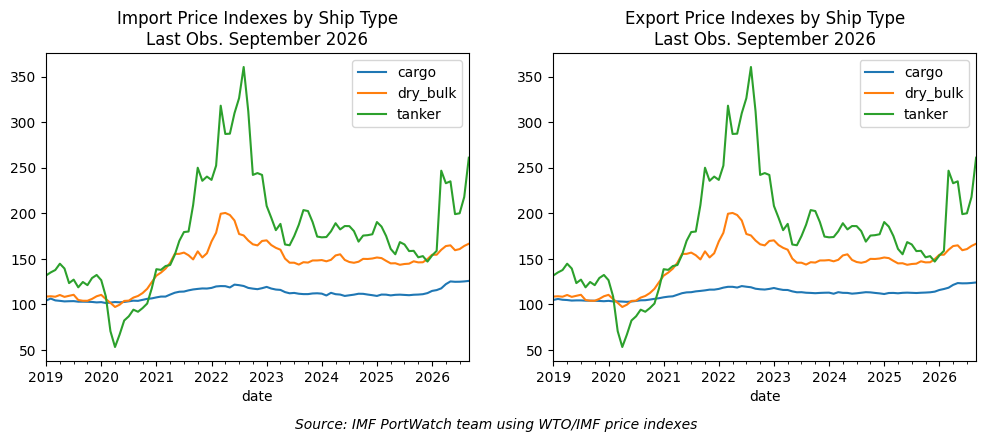

In [ ]:
# Get the latest date available in the index
price_indexes.index = pd.to_datetime(price_indexes.index)

latest_date = price_indexes.index.max().strftime('%B %Y')

# Create two subplots: one for import, one for export
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(12, 4))

# --- Plot Import Price Indexes ---
price_indexes.xs('import', axis=1, level=1).plot(
    legend=True,
    ax=axs[0],
    title=f"Import Price Indexes by Ship Type\nLast Obs. {latest_date}"
)

# --- Plot Export Price Indexes ---
price_indexes.xs('export', axis=1, level=1).plot(
    legend=True,
    ax=axs[1],
    title=f"Export Price Indexes by Ship Type\nLast Obs. {latest_date}"
)

# Add a footnote below the entire figure
fig.text(0.5, -0.05, 'Source: IMF PortWatch team using WTO/IMF price indexes',
         ha='center', va='center', fontsize=10, style='italic');


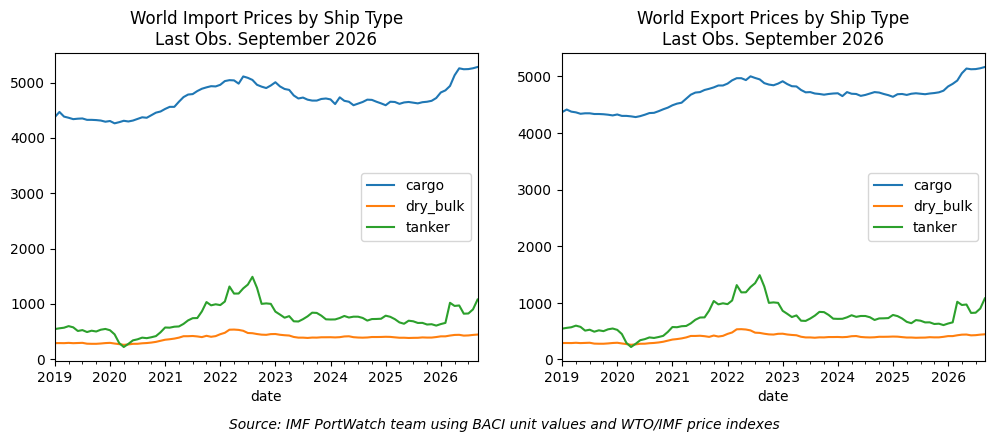

In [ ]:
# Get the latest date available in the index
prices.index = pd.to_datetime(prices.index)

latest_date = prices.index.max().strftime('%B %Y')

# Create two subplots: one for import, one for export
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(12, 4))

# --- Plot Import Price Indexes ---
prices.xs('import', axis=1, level=1).plot(
    legend=True,
    ax=axs[0],
    title=f"World Import Prices by Ship Type\nLast Obs. {latest_date}"
)

# --- Plot Export Price Indexes ---
prices.xs('export', axis=1, level=1).plot(
    legend=True,
    ax=axs[1],
    title=f"World Export Prices by Ship Type\nLast Obs. {latest_date}"
)

# Add a footnote below the entire figure
fig.text(0.5, -0.05, 'Source: IMF PortWatch team using BACI unit values and WTO/IMF price indexes',
         ha='center', va='center', fontsize=10, style='italic');


## Compute PWI Trade Value

<h4> 📘 Estimating Trade Value Indexes</h4>

 <details>
  <summary> This process transforms physical volumes (in metric tons) data from <b>PortWatch</b> into estimated <b>trade values</b> by combining it with BACI unit values and percentage changes in the average unit values. </summary>

From: *Arslanalp S., S. M. Choi, P. Kamali, R. Koepke, M. McKetty, M. Ruta, M. Saraiva, A. Sozzi, and J. Verschuur (2025), "Nowcasting Global Trade from Space," IMF Working Paper 25/93.*

* First, construct an average unit values of goods (US$/metric ton) transported by the different vessel types:
 - 🚢 Tanker,
 - 🚢 Dry Bulk, and
 - 🚢Containerships and other cargo vessels

* This allows us to calculate the global trade value, as shown below in Equations 1 and 2.

 </details>

 <details>
<summary> Formula </summary>

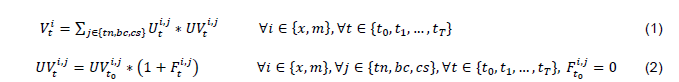


where:
-  <b> 𝑉𝑡𝑥 </b> and <b> 𝑉𝑡𝑚</b> are global exports and imports in value terms respectively at period t,
- <b>𝑈𝑡𝑥,𝑗 </b>and <b>𝑈𝑡𝑚,𝑗 </b>are global export and import shipments in physical volume respectively by vessel type j at period t, respectively [previously obtained],
- <b>𝑈𝑉𝑡𝑥,𝑗 </b>and <b>𝑈𝑉𝑡𝑚,𝑗 </b>are average unit values of goods exported and imported, respectively, by vessel type j at period t, and
- <b>𝐹𝑡𝑥,𝑗 </b> and <b>𝐹𝑡𝑚,𝑗 </b>are percentage changes in the average unit value of goods exported and imported, respectively, by vessel type j between the base period (to) and period t.

- In terms of vessel types (j), <b>tn, db, and cs</b> stand for <b>tanker, dry bulk carrier,</b> and <b>containership/other cargo vessel</b>, respectively.



#### Import/Export Values

In [ ]:
# Compute trade value series from combination of PortWatch import/export physical volumes
# with prices by vessel types. Add the total trade values as well.
values = to_value_series(
    portwatch=portwatch,
    prices=prices
)

values.tail().div(10**9)

cargo                 dry_bulk                   tanker  \
                 export       import      export      import       export   
date                                                                        
2026-05-01  7912.127045  8116.605540  828.032880  798.964036  1207.825492   
2026-06-01  7779.881890  7813.346825  790.054605  770.460787  1035.279650   
2026-07-01  7758.194941  7998.266406  754.216596  790.687413  1034.587976   
2026-08-01  7794.763946  7850.423491  773.365495  766.558056  1078.334714   
2026-09-01  7700.748523  7747.939294  761.765078  761.428832  1230.288449   

                                total               
                 import        import       export  
date                                                
2026-05-01  1390.362027  10305.931603  9947.985417  
2026-06-01  1134.498379   9718.305991  9605.216145  
2026-07-01  1226.140341  10015.094161  9546.999514  
2026-08-01  1284.097712   9901.079260  9646.464155  
2026-09-01  1447.531387   9956.899514  9692.802050

#### Convert to Indexes

In [ ]:
value_indexes = to_index(df=values,
                         base_year=2019) # The to_index function normalizes the value time series by setting a base period

# Show the last few rows of the resulting DataFrame
value_indexes.tail()


cargo                dry_bulk                  tanker  \
                export      import      export      import      export   
date                                                                     
2026-05-01  137.464547  142.417966  166.928747  162.878793  193.728122   
2026-06-01  135.166932  137.096839  159.272450  157.068050  166.052781   
2026-07-01  134.790145  140.341530  152.047624  161.191501  165.941841   
2026-08-01  135.425491  137.747405  155.907980  156.272430  172.958561   
2026-09-01  133.792076  135.949167  153.569373  155.226773  197.331048   

                             total              
                import      import      export  
date                                            
2026-05-01  194.241371  149.243187  144.692451  
2026-06-01  158.495784  140.733610  139.706906  
2026-07-01  171.298680  145.031486  138.860151  
2026-08-01  179.395650  143.380403  140.306855  
2026-09-01  202.228251  144.188752  140.980835

#### Plots

<h4> 🎯 PortWatch-derived import/export <b>value indexes</b> </h4>

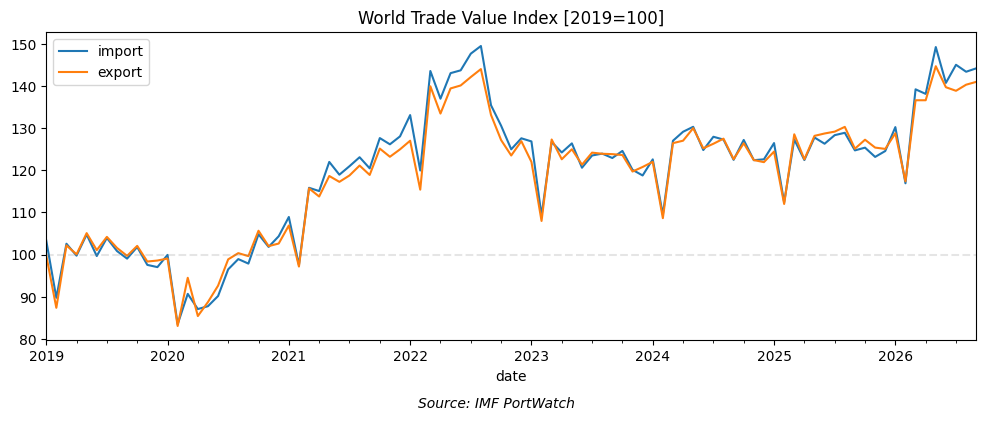

In [ ]:
# Create plot
fig, ax = plt.subplots(figsize=(12, 4))

# --- Plot Value Import/Export Indexes ---
value_indexes[('total', 'import')].plot(
    label="import",
    ax=ax,
    legend=True)
value_indexes[('total', 'export')].plot(
    label="export",
    ax=ax,
    legend=True)

plt.title('World Trade Value Index [2019=100]')

# Add 0 line
plt.hlines(y=100,
           xmin=value_indexes.index.min(),
           xmax=value_indexes.index.max(),
           alpha=0.2, colors='grey', linestyles='--')

# Add a footnote below the entire figure
fig.text(0.5, -0.05, 'Source: IMF PortWatch',
         ha='center', va='center', fontsize=10, style='italic');

## Compute PWI Trade Volume

<h4> 📘 Estimating Trade Volume Indexes </h4>

 <details>
  <summary> This process transforms import/export trade values (in $) derived in previous step into estimated <b>trade volume  (in constant prices)</b> using import/export price deflators. </summary>

From: *Arslanalp S., S. M. Choi, P. Kamali, R. Koepke, M. McKetty, M. Ruta, M. Saraiva, A. Sozzi, and J. Verschuur (2025), "Nowcasting Global Trade from Space," IMF Working Paper 25/93.*

* First, to compute export/import price deflators, we construct a Laspeyres-type index   

* This allows us to calculate the global trade volume, as shown below in Equations 3.

 </details>

 <details>
<summary> Formula </summary>

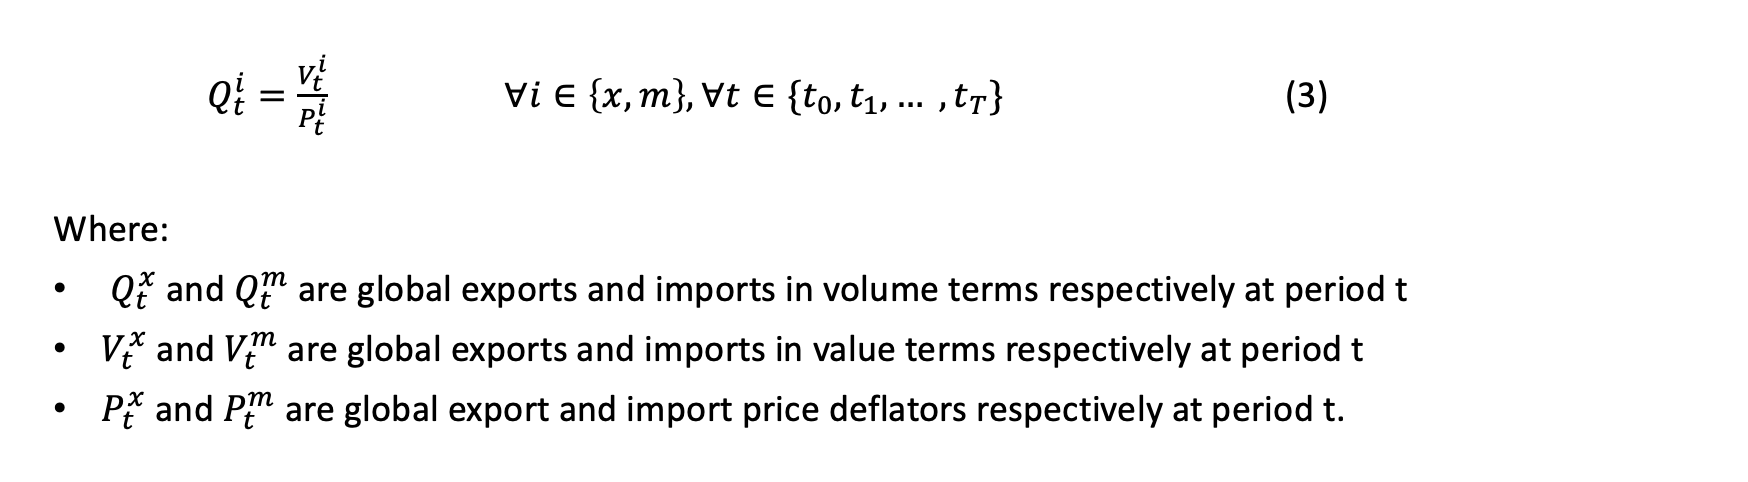

For export/import price deflators, we use a Laspeyres-type index. This is to mimic the approach used by many national statistical agencies, including those in the euro area and the United States. The Laspeyres-type index applies the base period quantities for both the base period and the period for which the index is computed to estimate the price effect, as shown in Equation 4.

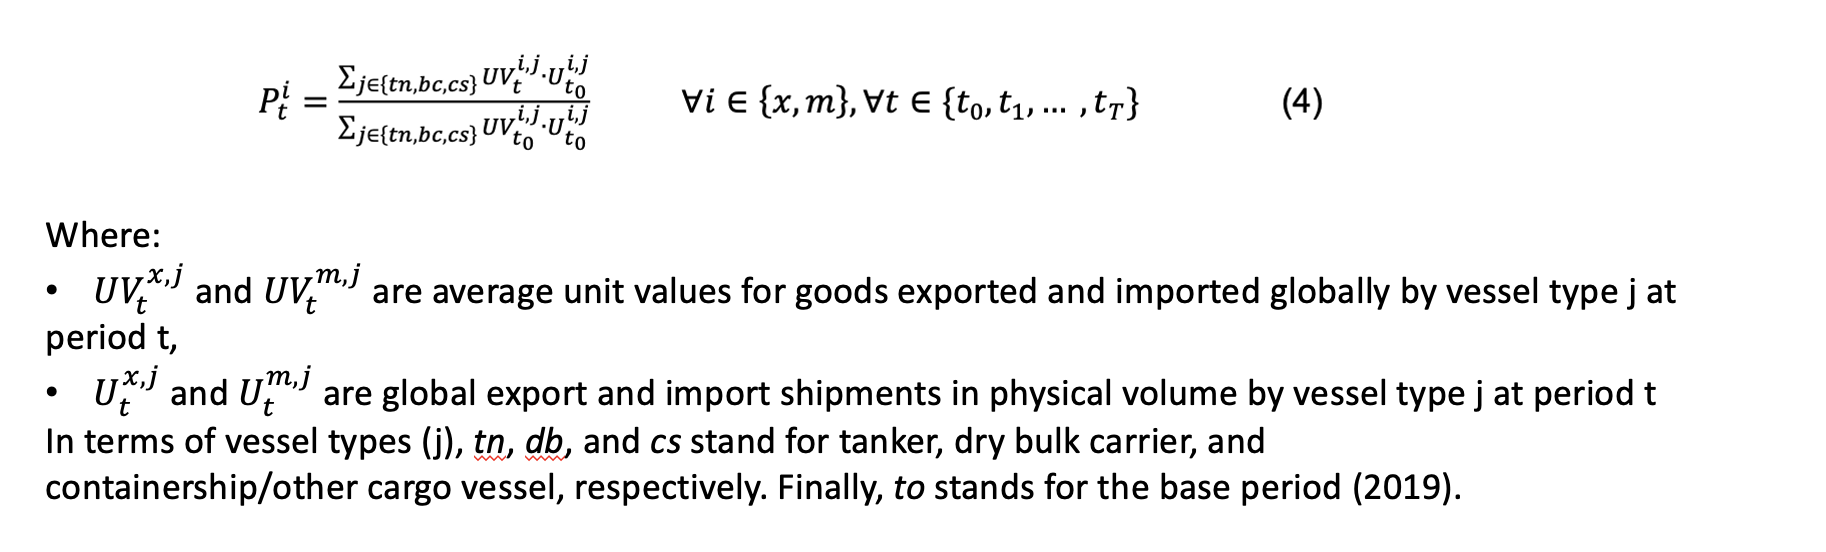

 </details>

#### Import/Export Price Deflators

In [ ]:
# Calculate import/export price indexes deflators using Laspeyres-type index
chpis = to_laspeyres_price_index(portwatch=portwatch, prices=prices)

print(chpis.shape)

chpis.tail()

(93, 2)


,export,import
date,,
2026-05-01,126.278894,129.272296
2026-06-01,123.177747,125.742705
2026-07-01,123.378228,125.951409
2026-08-01,125.128838,127.877080
2026-09-01,128.722730,131.898099


<Axes: xlabel='date'>

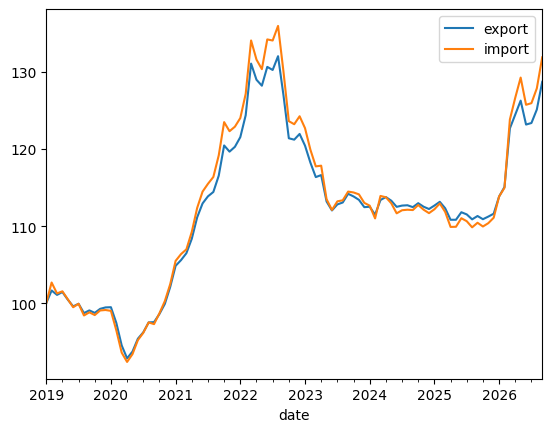

In [ ]:
chpis.plot()

#### Import/Export Volumes

In [ ]:
volume = to_volume_weighted_series(chained_price_index=chpis, values=values)
volume.tail()

,export,import
date,,
2026-05-01,7.877789e+10,7.972266e+10
2026-06-01,7.797850e+10,7.728724e+10
2026-07-01,7.737994e+10,7.951554e+10
2026-08-01,7.709225e+10,7.742654e+10
2026-09-01,7.529985e+10,7.548933e+10


#### Convert to Indexes

In [ ]:
volume_indexes = to_index(df=volume, base_year=2019)
volume_indexes.tail()

,export,import
date,,
2026-05-01,114.503132,115.348388
2026-06-01,113.341219,111.824639
2026-07-01,112.471209,115.048707
2026-08-01,112.053064,112.026189
2026-09-01,109.447815,109.223307


#### Plot

<h4> 🎯 PortWatch-derived import/export <b>volume indexes</b> </h4>

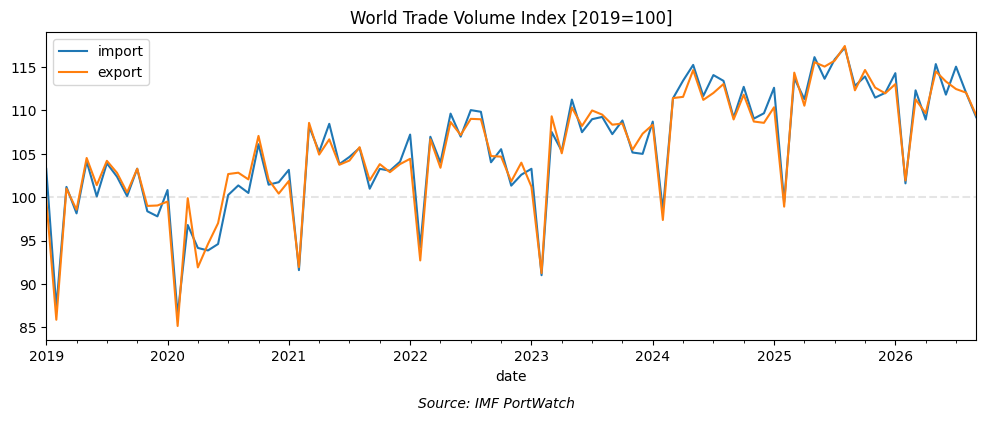

In [ ]:
# Create plot
fig, ax = plt.subplots(figsize=(12, 4))

# --- Plot Volume Import/Export Indexes ---
volume_indexes['import'].plot(
    label="import",
    ax=ax,
    legend=True)
volume_indexes['export'].plot(
    label="export",
    ax=ax,
    legend=True)

plt.title('World Trade Volume Index [2019=100]')

# Add 0 line
plt.hlines(y=100,
           xmin=volume_indexes.index.min(),
           xmax=volume_indexes.index.max(),
           alpha=0.2, colors='grey', linestyles='--')

# Add a footnote below the entire figure
fig.text(0.5, -0.05, 'Source: IMF PortWatch',
         ha='center', va='center', fontsize=10, style='italic');

## Combine Import/Export Value and Volume Indexes into a single dataset

In [ ]:
trade_df = (
    pd.concat([value_indexes['total'].rename(columns={c:'value_'+c for c in value_indexes['total'].columns}),
               volume_indexes.rename(columns={c:'volume_'+c for c in volume_indexes.columns})], axis=1)
)

trade_df

,value_import,value_export,volume_export,volume_import
date,,,,
2019-01-01,103.358375,99.834019,99.765600,103.268567
2019-02-01,89.737672,87.359406,85.876257,87.311142
2019-03-01,102.567675,102.163206,100.996905,101.190212
2019-04-01,99.744148,100.066032,98.564596,98.136109
2019-05-01,104.760762,105.083905,104.522435,104.130697
...,...,...,...,...
2026-05-01,149.243187,144.692451,114.503132,115.348388
2026-06-01,140.733610,139.706906,113.341219,111.824639
2026-07-01,145.031486,138.860151,112.471209,115.048707


In [ ]:
trade_df.to_csv(os.path.join(data_path, 'pw_global_trade_nowcast.csv'))

## Comparison with Official data from CPB World Trade Monitor

Source: https://www.cpb.nl/en/worldtrademonitor

In [ ]:
# Get the most recent data from CPB

# PW functions
cpb_value, cpb_volume = fetch_and_tweak(fetch_cpb, tweak_cpb)

print("CPB Estimates for regions: ", cpb_value.index.levels[0].to_list())

# Filter for World
cpb_value = cpb_value.loc['World']
cpb_volume = cpb_volume.loc['World']

cpb_value.tail()

CPB Estimates for regions:  ['Advanced Asia excl Japan', 'Advanced Economies', 'Africa and Middle East', 'China', 'Eastern Europe / CIS', 'Emerging Asia excl China', 'Emerging Economies', 'Euro Area', 'Japan', 'Latin America', 'Other Advanced Economies', 'United Kingdom', 'United States', 'World']


flow,import,export
date,,
2026-04-01,154.891534,157.644088
2026-05-01,157.556031,159.771663
2026-06-01,158.194510,161.524471
2026-07-01,157.932509,161.282154
2026-08-01,161.685344,164.332946


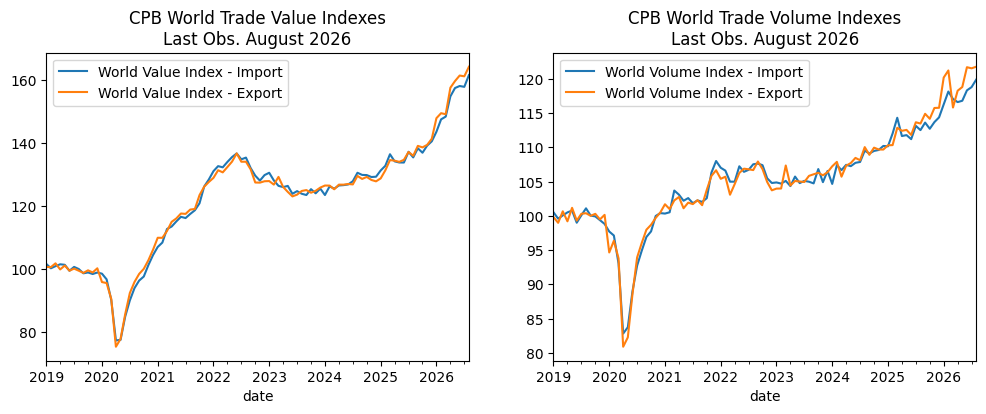

In [ ]:
# Get the most recent date from the CPB
latest_date = pd.to_datetime(cpb_value.index.max()).strftime('%B %Y')

# Create side-by-side subplots for value and volume indexes
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(12, 4))

# --- Plot 1: Trade Value Indexes ---
# Plot Import Value Index
cpb_value['import'].plot(
    label='World Value Index - Import', legend=True, ax=axs[0]
)

# Plot Export Value Index with title
cpb_value['export'].plot(
    label='World Value Index - Export',
    legend=True,
    ax=axs[0],
    title=f"CPB World Trade Value Indexes\nLast Obs. {latest_date}"
)

# --- Plot 2: Trade Volume Indexes ---
# Plot Import Volume Index
cpb_volume['import'].plot(
    label='World Volume Index - Import', legend=True, ax=axs[1]
)

# Plot Export Volume Index with title
cpb_volume['export'].plot(
    label='World Volume Index - Export',
    legend=True,
    ax=axs[1],
    title=f"CPB World Trade Volume Indexes\nLast Obs. {latest_date}"
);

<h3> 🎯 Compare PortWatch-derived trade value and volume indexes  with CPB indexes </h3>



In [ ]:
pw_indexes_3ma = moving_avg(df=trade_df, period=3)
trade_df.head()

,value_import,value_export,volume_export,volume_import
date,,,,
2019-01-01,103.358375,99.834019,99.765600,103.268567
2019-02-01,89.737672,87.359406,85.876257,87.311142
2019-03-01,102.567675,102.163206,100.996905,101.190212
2019-04-01,99.744148,100.066032,98.564596,98.136109
2019-05-01,104.760762,105.083905,104.522435,104.130697


In [ ]:
# Prepare series and compute correlations - Import Values
imp_val_cbp = cpb_value['import']
imp_val_pw = trade_df['value_import']
imp_correlation = correlate(imp_val_cbp, imp_val_pw)
imp_correlation

np.float64(0.9)

In [ ]:
# Prepare series and compute correlations - Export Values
exp_val_cbp = cpb_value['export']
exp_val_pw = trade_df['value_export']
exp_correlation = correlate(exp_val_cbp, exp_val_pw)
exp_correlation

np.float64(0.9)

In [ ]:
# Prepare series and compute correlations - Import Volumes
imp_vol_cbp = cpb_volume['import']
imp_vol_pw = trade_df['volume_import']
imp_vol_correlation = correlate(imp_vol_cbp, imp_vol_pw)
imp_vol_correlation


np.float64(0.71)

In [ ]:
# Prepare series and compute correlations - Export Volumes
exp_vol_cbp = cpb_volume['export']
exp_vol_pw = trade_df['volume_export']
exp_vol_correlation = correlate(exp_vol_cbp, exp_vol_pw)
exp_vol_correlation

np.float64(0.69)

In [ ]:
def plot_series(ax, s1, s2, label1, label2, title):
    """Plot two time series on the same axis."""
    s1.plot(ax=ax, label=label1, legend=True)
    s2.plot(ax=ax, label=label2, legend=True)
    ax.set_title(title)

<h4> 🎯 Compare PortWatch-derived <b>value index</b>  vs. CPB <b>value index</b> </h4>

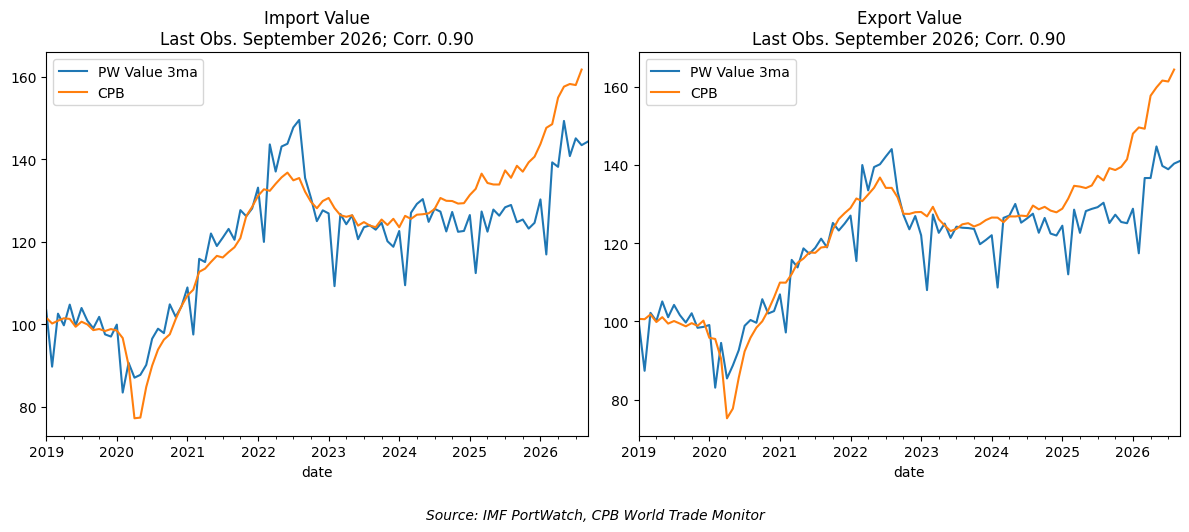

In [ ]:
# Format latest date
latest_date = trade_df.index.max().strftime('%B %Y')

# Create Values plots
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(12, 5))

plot_series(
    axs[0], imp_val_pw, imp_val_cbp,
    label1='PW Value 3ma', label2='CPB',
    title=f"Import Value\nLast Obs. {latest_date}; Corr. {imp_correlation:.2f}"
)

plot_series(
    axs[1], exp_val_pw, exp_val_cbp,
    label1='PW Value 3ma', label2='CPB',
    title=f"Export Value\nLast Obs. {latest_date}; Corr. {exp_correlation:.2f}"
)

# Source note and layout
fig.text(0.5, -0.05, "Source: IMF PortWatch, CPB World Trade Monitor", ha='center', fontsize=10, style='italic')
plt.tight_layout()
plt.show()


<h4> 🎯 Compare PortWatch-derived <b>volume index</b>  vs. CPB <b>volume index</b> </h4>



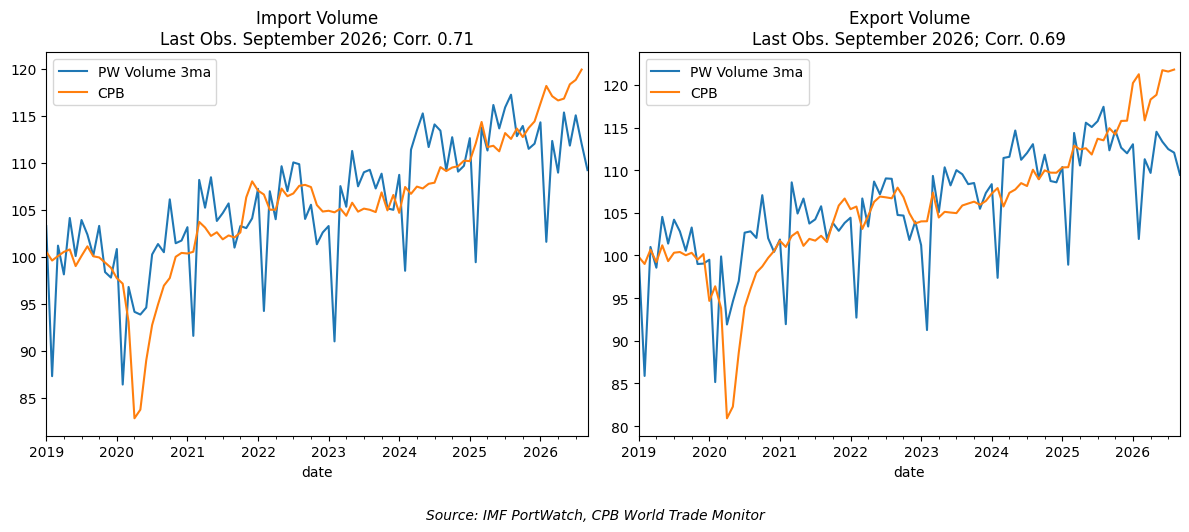

In [ ]:
# Format latest date
latest_date = trade_df.index.max().strftime('%B %Y')

# --- Create Volume plots ---
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(12, 5))

plot_series(
    axs[0], imp_vol_pw, imp_vol_cbp,
    label1='PW Volume 3ma', label2='CPB',
    title=f"Import Volume\nLast Obs. {latest_date}; Corr. {imp_vol_correlation:.2f}"
)

plot_series(
    axs[1], exp_vol_pw, exp_vol_cbp,
    label1='PW Volume 3ma', label2='CPB',
    title=f"Export Volume\nLast Obs. {latest_date}; Corr. {exp_vol_correlation:.2f}"
)

# Source note and layout
fig.text(0.5, -0.05, "Source: IMF PortWatch, CPB World Trade Monitor", ha='center', fontsize=10, style='italic')
plt.tight_layout()
plt.show()



## Annex

### Data Sources

The notebook requires input data from several sources:
| Input Source                          | Link                                                                 |
|---------------------------------|----------------------------------------------------------------------|
| IMF PortWatch                   | [portwatch.imf.org](https://portwatch.imf.org/pages/data-and-methodology) |
| IMF Primary Commodity Prices    | [IMF PCP](https://www.imf.org/en/Research/commodity-prices-)        |
| CEPII - Base pour l'Analyse du Commerce International                           | [CEPII-BACI](https://www.cepii.fr/CEPII/en/bdd_modele/bdd_modele_item.asp?id=37)                                                 |
| US CPI (U.S. Bureau of Labor Statistics API)                | [api.bls.gov](https://api.bls.gov/publicAPI/v1/timeseries/data/)        |
| Federal Reserve Bank of Cleveland CPI                   | [clevelandfed.org](https://www.clevelandfed.org/indicators-and-data/inflation-nowcasting) |
| WTO -  Import and Export price indices of manufactured goods       | [api.wto.org](https://api.wto.org/timeseries/v1/data?)              |
| CPB World Trade Monitor         | [cpb.nl](https://www.cpb.nl/en/worldtrademonitor)                   |


### Country Composition of WEO Groups
Source: [IMF World Economic Outlook Database (April 2023)](https://www.imf.org/en/Publications/WEO/weo-database/2023/April/groups-and-aggregates)


| Source | Code | Name                                                | # Countries |
|:-------:|:----:|:---------------------------------------------------|-------------:|
| WEO | WLD | World | All |
| WEO | 110 | Advanced Economies | 41 |
| WEO | 163 | Euro Area | 20 |
| WEO | 119 | Major Advanced Economies (G7) | 7 |
| WEO | 123 | Other Advanced Economies (Advanced Economies excluding G7 and Euro Area) | 17 |
| WEO | 998 | European Union | 27 |
| WEO | 510 | ASEAN-5 | 5 |
| WEO | 200 | Emerging Market and Developing Economies | 0 |
| WEO | 505 | Emerging and Developing Asia | 0 |
| WEO | 903 | Emerging and Developing Europe | 0 |
| WEO | 205 | Latin America and the Caribbean | 0 |
| WEO | 400 | Middle East and Central Asia | 0 |
| WEO | 603 | Sub-Saharan Africa | 0 |
| APD | 511 | Asian Advanced Economies excluding Japan | 7 |
| APD | 512 | Asian Emerging Markets excluding China | 25 |
| APD | 513 | ASEAN-10 | 9 |
